# Classification des battements ECG

## Objectif
Entraîner des modèles de Machine Learning pour classifier
les battements ECG en deux catégories :

- 0 : Normal
- 1 : Anormal

Modèles étudiés :
- K-Nearest Neighbors (KNN)
- Random Forest
- KNN avec réduction de dimension PCA

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Réduction de dimension
from sklearn.decomposition import PCA

# Séparation des données
from sklearn.model_selection import train_test_split

# Évaluation des modèles
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
normal = pd.read_csv("../data/ptbdb_normal.csv", header=None)
abnormal = pd.read_csv("../data/ptbdb_abnormal.csv", header=None)

df = pd.concat([normal, abnormal], ignore_index=True)

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [4]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (11641, 187)
X_test : (2911, 187)
y_train : (11641,)
y_test : (2911,)


In [6]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [7]:
y_pred = knn.predict(X_test)

In [8]:
print("Prédictions :", y_pred[:10])
print("Vraies classes :", y_test.iloc[:10].values)

Prédictions : [1. 1. 0. 0. 1. 1. 0. 0. 1. 0.]
Vraies classes : [1. 1. 0. 0. 1. 1. 0. 0. 1. 0.]


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy * 100, "%")

Accuracy : 92.99209893507386 %


In [10]:
cm = confusion_matrix(y_test, y_pred) 
print(cm)

[[ 728   81]
 [ 123 1979]]


In [12]:
recall = recall_score(y_test, y_pred)

print("Recall :", recall * 100, "%")

precision = precision_score(y_test, y_pred)

print("Precision :", precision * 100, "%")

Recall : 94.14843006660324 %
Precision : 96.06796116504854 %


In [13]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)

print("F1-score :", f1 * 100, "%")

F1-score : 95.09851033157136 %


In [14]:
bilan = {
    "Métrique": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
}

df_bilan = pd.DataFrame(bilan)

In [15]:
df_bilan

,Métrique,Score (%)
0,Accuracy,92.992099
1,Precision,96.067961
2,Recall,94.148430
3,F1-score,95.098510


In [16]:

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [17]:
y_pred_rf = rf.predict(X_test)

In [18]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

In [19]:
comparaison = {
    "Métrique": ["Accuracy", "Precision", "Recall", "F1-score"],
    "KNN (%)": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ],
    "Random Forest (%)": [
        accuracy_rf * 100,
        precision_rf * 100,
        recall_rf * 100,
        f1_rf * 100
    ]
}

df_comparaison = pd.DataFrame(comparaison)

display(df_comparaison.round(2))

,Métrique,KNN (%),Random Forest (%)
0,Accuracy,92.99,97.05
1,Precision,96.07,97.01
2,Recall,94.15,98.95
3,F1-score,95.10,97.97


In [20]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[ 745   64]
 [  22 2080]]


In [21]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [22]:
print("Avant PCA :", X_train.shape)
print("Après PCA :", X_train_pca.shape)
print("Test PCA :", X_test_pca.shape)

Avant PCA : (11641, 187)
Après PCA : (11641, 36)
Test PCA : (2911, 36)


In [23]:
knn_pca = KNeighborsClassifier(n_neighbors=5)

knn_pca.fit(X_train_pca, y_train)

y_pred_pca = knn_pca.predict(X_test_pca)

In [24]:
accuracy_pca = accuracy_score(y_test, y_pred_pca)
precision_pca = precision_score(y_test, y_pred_pca)
recall_pca = recall_score(y_test, y_pred_pca)
f1_pca = f1_score(y_test, y_pred_pca)

In [25]:
df_comparaison["KNN + PCA (%)"] = [
    accuracy_pca * 100,
    precision_pca * 100,
    recall_pca * 100,
    f1_pca * 100
]

display(df_comparaison.round(2))

,Métrique,KNN (%),Random Forest (%),KNN + PCA (%)
0,Accuracy,92.99,97.05,93.34
1,Precision,96.07,97.01,95.82
2,Recall,94.15,98.95,94.91
3,F1-score,95.10,97.97,95.36


In [26]:
import time

debut = time.perf_counter()
knn.predict(X_test)
temps_knn = time.perf_counter() - debut

debut = time.perf_counter()
knn_pca.predict(X_test_pca)
temps_pca = time.perf_counter() - debut

print("KNN original :", round(temps_knn, 3), "secondes")
print("KNN + PCA :", round(temps_pca, 3), "secondes")

KNN original : 0.205 secondes
KNN + PCA : 0.045 secondes


### Comparaison des modèles et impact de la PCA

Trois configurations ont été évaluées sur le dataset PTBDB : KNN, Random Forest et KNN avec réduction de dimension PCA.

**Random Forest** obtient les meilleures performances globales, avec une accuracy de **97,05 %**, un rappel de **98,95 %** et un F1-score de **97,97 %** pour la classe anormale.

L'application de la PCA à KNN a permis de réduire le nombre de caractéristiques de 187 à 36, tout en améliorant légèrement son accuracy de 92,99 % à 93,34 %.

Le temps de prédiction mesuré est passé de 0,205 seconde à 0,045 seconde, soit une accélération d'environ 4,6 fois, hors coût de transformation PCA.

Ces résultats illustrent l'intérêt potentiel de la réduction de dimension pour améliorer l'efficacité des modèles.

**Limite :** les données ont été séparées aléatoirement par battement et non par patient. Les performances rapportées sont exploratoires et ne constituent pas une validation clinique.

In [27]:
from sklearn.model_selection import GridSearchCV
parametres = {
    "n_neighbors": [3, 5, 7, 9, 11]
}

In [28]:
grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=parametres,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

In [29]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [3, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with higherv

In [30]:
print("Meilleur K :", grid.best_params_)
print("Meilleur recall CV :", grid.best_score_ * 100, "%")

Meilleur K : {'n_neighbors': 3}
Meilleur recall CV : 94.46692020056089 %


In [31]:
knn_optimise = grid.best_estimator_
y_pred_opt = knn_optimise.predict(X_test)

In [32]:
accuracy_opt = accuracy_score(y_test, y_pred_opt)
precision_opt = precision_score(y_test, y_pred_opt)
recall_opt = recall_score(y_test, y_pred_opt)
f1_opt = f1_score(y_test, y_pred_opt)

In [33]:
df_comparaison["KNN optimisé (%)"] = [
    accuracy_opt * 100,
    precision_opt * 100,
    recall_opt * 100,
    f1_opt * 100
]

display(df_comparaison.round(2))

,Métrique,KNN (%),Random Forest (%),KNN + PCA (%),KNN optimisé (%)
0,Accuracy,92.99,97.05,93.34,93.89
1,Precision,96.07,97.01,95.82,96.65
2,Recall,94.15,98.95,94.91,94.81
3,F1-score,95.10,97.97,95.36,95.73


In [34]:
parametres_rf = {
    "n_estimators": [50, 100, 150],
    "max_depth": [10, 20, None]
}

In [37]:
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(),
    param_grid=parametres_rf,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

In [38]:
grid_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information pr

In [39]:
print("Meilleurs paramètres :", grid_rf.best_params_)
print("Meilleur recall CV :", grid_rf.best_score_ * 100, "%")

Meilleurs paramètres : {'max_depth': None, 'n_estimators': 150}
Meilleur recall CV : 98.7624359083312 %


In [40]:
rf_optimise = grid_rf.best_estimator_

y_pred_rf_opt = rf_optimise.predict(X_test)


In [41]:
accuracy_rf_opt = accuracy_score(y_test, y_pred_rf_opt)
precision_rf_opt = precision_score(y_test, y_pred_rf_opt)
recall_rf_opt = recall_score(y_test, y_pred_rf_opt)
f1_rf_opt = f1_score(y_test, y_pred_rf_opt)

In [42]:
df_comparaison["Random Forest optimisé (%)"] = [
    accuracy_rf_opt * 100,
    precision_rf_opt * 100,
    recall_rf_opt * 100,
    f1_rf_opt * 100
]

display(df_comparaison.round(2))

,Métrique,KNN (%),Random Forest (%),KNN + PCA (%),KNN optimisé (%),Random Forest optimisé (%)
0,Accuracy,92.99,97.05,93.34,93.89,97.29
1,Precision,96.07,97.01,95.82,96.65,97.16
2,Recall,94.15,98.95,94.91,94.81,99.14
3,F1-score,95.10,97.97,95.36,95.73,98.14


In [43]:
cm_rf_opt = confusion_matrix(y_test, y_pred_rf_opt)

print(cm_rf_opt)

[[ 748   61]
 [  18 2084]]


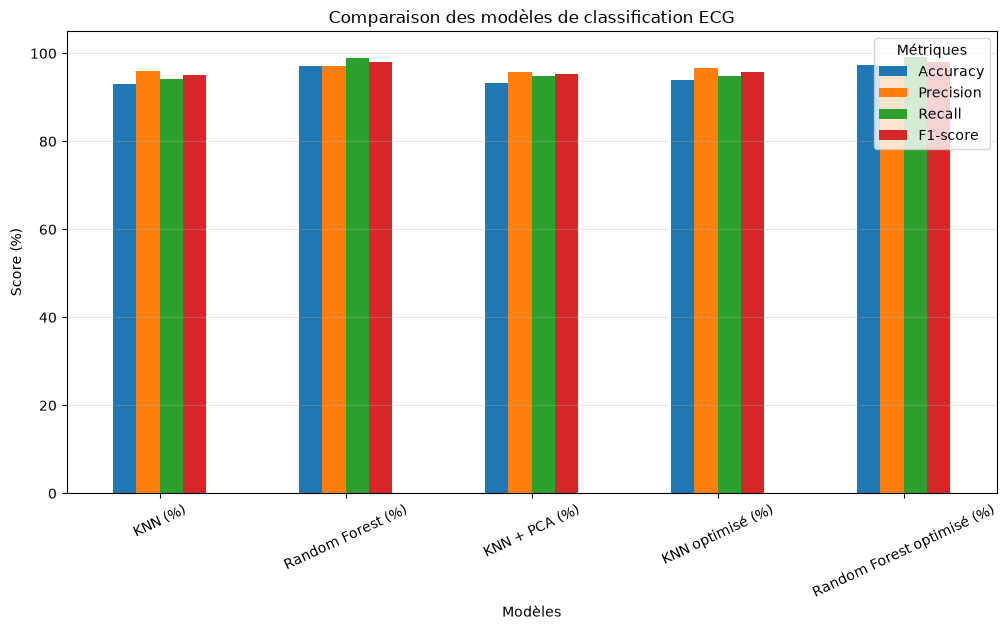

In [44]:
import matplotlib.pyplot as plt

df_comparaison.set_index("Métrique").T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparaison des modèles de classification ECG")
plt.xlabel("Modèles")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=25)
plt.legend(title="Métriques")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [45]:
from sklearn.decomposition import PCA

pca_visu = PCA(n_components=2)

pca_visu.fit(X_train)

X_test_2d = pca_visu.transform(X_test)

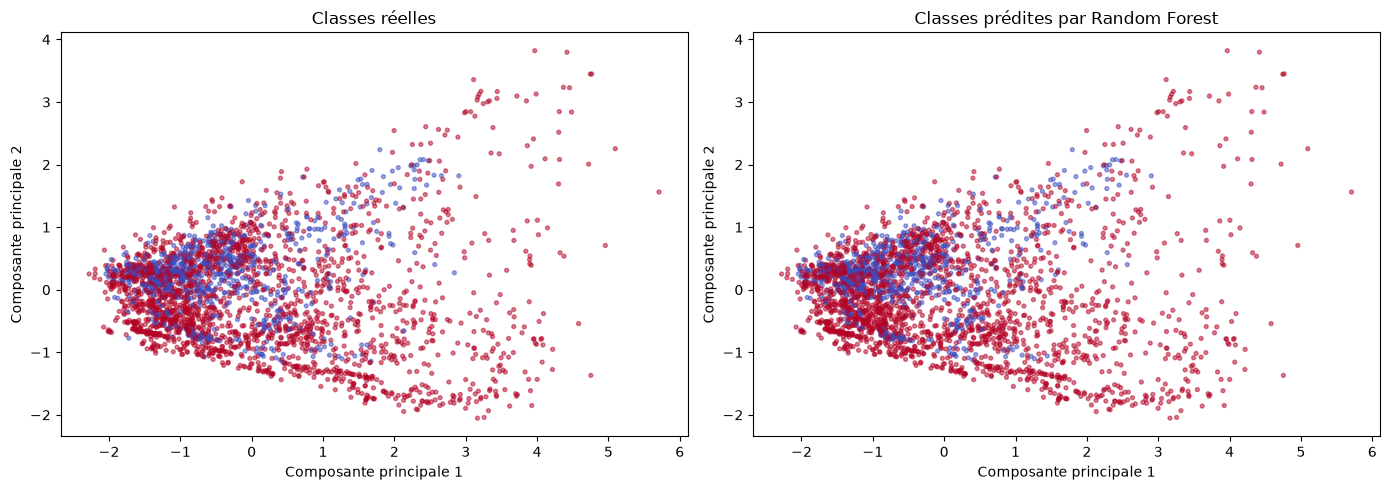

In [46]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_test,
    cmap="coolwarm",
    s=8,
    alpha=0.5
)

axes[0].set_title("Classes réelles")

axes[1].scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=y_pred_rf_opt,
    cmap="coolwarm",
    s=8,
    alpha=0.5
)

axes[1].set_title("Classes prédites par Random Forest")

for ax in axes:
    ax.set_xlabel("Composante principale 1")
    ax.set_ylabel("Composante principale 2")

plt.tight_layout()
plt.show()

In [47]:
erreurs = (y_test.to_numpy() != y_pred_rf_opt)

print("Nombre d'erreurs :", erreurs.sum())

Nombre d'erreurs : 79


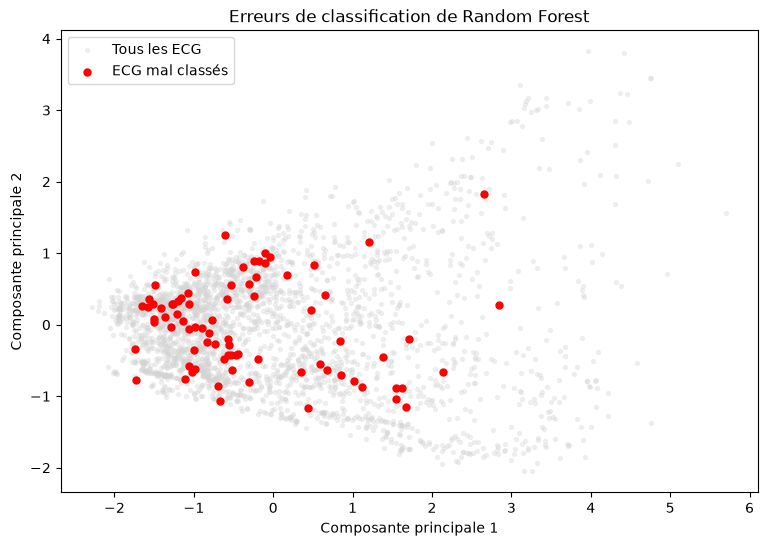

In [48]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c="lightgray",
    s=8,
    alpha=0.3,
    label="Tous les ECG"
)

plt.scatter(
    X_test_2d[erreurs, 0],
    X_test_2d[erreurs, 1],
    c="red",
    s=25,
    label="ECG mal classés"
)

plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Erreurs de classification de Random Forest")
plt.legend()
plt.show()

In [51]:
y_reel = np.asarray(y_test)

faux_negatifs = (y_reel == 1) & (y_pred_rf_opt == 0)
print("Nombre de faux négatifs :", faux_negatifs.sum())

Nombre de faux négatifs : 18


In [52]:
X_faux_negatifs = X_test.loc[faux_negatifs]

print(X_faux_negatifs.shape)

(18, 187)


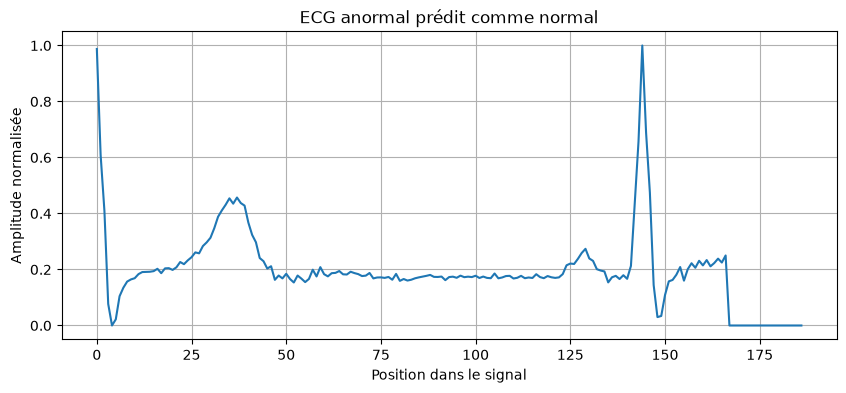

In [53]:
plt.figure(figsize=(10, 4))

plt.plot(X_faux_negatifs.iloc[0].to_numpy())

plt.title("ECG anormal prédit comme normal")
plt.xlabel("Position dans le signal")
plt.ylabel("Amplitude normalisée")
plt.grid(True)
plt.show()

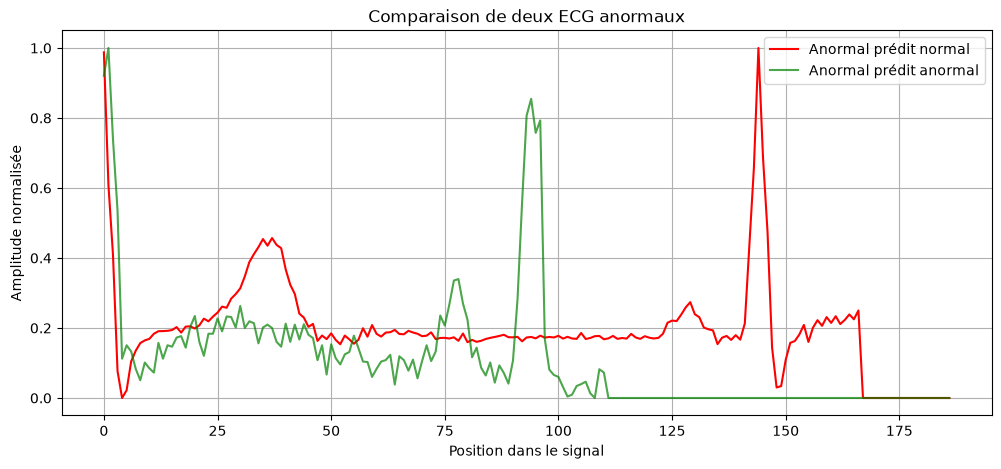

In [54]:
bien_classes = (y_reel == 1) & (y_pred_rf_opt == 1)

X_bien_classes = X_test.loc[bien_classes]

plt.figure(figsize=(12, 5))

plt.plot(
    X_faux_negatifs.iloc[0].to_numpy(),
    label="Anormal prédit normal",
    color="red"
)

plt.plot(
    X_bien_classes.iloc[0].to_numpy(),
    label="Anormal prédit anormal",
    color="green",
    alpha=0.7
)

plt.xlabel("Position dans le signal")
plt.ylabel("Amplitude normalisée")
plt.title("Comparaison de deux ECG anormaux")
plt.legend()
plt.grid(True)
plt.show()

Notre modèle a correctement reconnu la courbe verte comme anormale, mais il a prédit que la courbe rouge était normale.

Une hypothèse serait que certaines caractéristiques de la courbe rouge ressemblent à celles des ECG normaux présents dans l'entraînement.

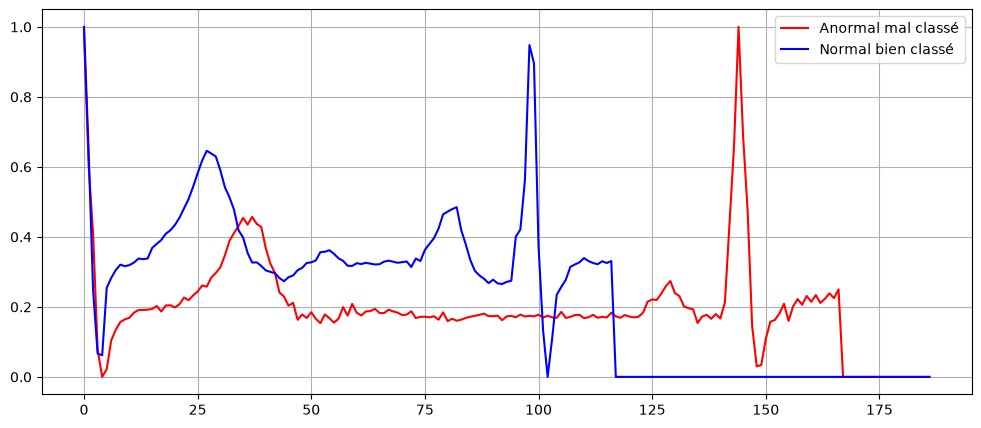

In [55]:
normaux = (y_reel == 0) & (y_pred_rf_opt == 0)

X_normaux = X_test.loc[normaux]

plt.figure(figsize=(12, 5))

plt.plot(
    X_faux_negatifs.iloc[0].to_numpy(),
    label="Anormal mal classé",
    color="red"
)

plt.plot(
    X_normaux.iloc[0].to_numpy(),
    label="Normal bien classé",
    color="blue"
)

plt.legend()
plt.grid(True)
plt.show()

In [57]:
probas = rf_optimise.predict_proba(X_test)

print(probas[0])

[0.5 0.5]


In [58]:
probas_faux_negatifs = probas[faux_negatifs]

print(probas_faux_negatifs[:5])

[[0.5        0.5       ]
 [0.68       0.32      ]
 [0.52666667 0.47333333]
 [0.54666667 0.45333333]
 [0.52666667 0.47333333]]


### l'importance des caractéristiques (Feature Importance) de notre Random Forest.

Notre modèle utilise 187 valeurs par ECG pour effectuer sa classification.

Nous voulons savoir quelles positions du signal ont le plus influencé les décisions du modèle

In [59]:
importances = rf_optimise.feature_importances_

print(importances.shape)
print(importances[:10])

(187,)
[0.00099241 0.00624569 0.01273065 0.02968708 0.04352601 0.01461051
 0.00618449 0.00662042 0.0059633  0.00428616]


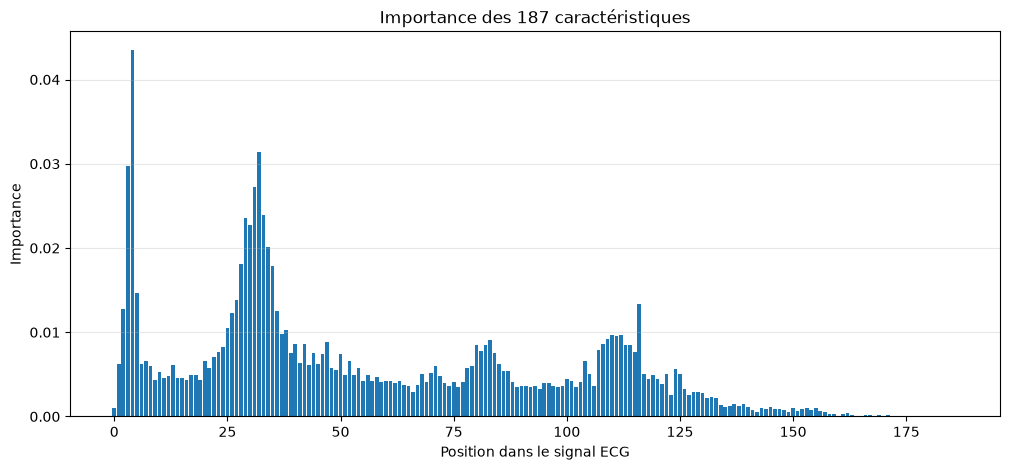

In [60]:
plt.figure(figsize=(12, 5))

plt.bar(range(187), importances)

plt.xlabel("Position dans le signal ECG")
plt.ylabel("Importance")
plt.title("Importance des 187 caractéristiques")
plt.grid(axis="y", alpha=0.3)

plt.show()

on remarque trois zones intéressantes :
- Positions 3 à 6 : un pic très important, avec un maximum autour de 0,0435.
- Positions 25 à 40 : plusieurs caractéristiques importantes, notamment autour de la position 32.
- Positions 108 à 117 : un autre groupe de caractéristiques relativement importantes.
À partir de la position 135 environ, les scores deviennent très faibles.

Cela suggère que le modèle utilise certaines régions du signal davantage que d'autres.

In [61]:
top_5 = np.argsort(importances)[-5:][::-1]

for position in top_5:
    print(f"Position {position} : {importances[position]:.4f}")
    

Position 4 : 0.0435
Position 32 : 0.0314
Position 3 : 0.0297
Position 31 : 0.0272
Position 33 : 0.0239


On remarque deux zones principales : les positions 3 à 4 et 31 à 33.

Cela signifie que notre Random Forest s'appuie particulièrement sur les valeurs du signal situées dans ces régions pour effectuer ses séparations.

Ces cinq caractéristiques représentent ensemble environ 15,57 % de l'importance totale.

Cela ne veut pas dire qu'elles suffisent à classifier correctement un ECG, ni qu'elles correspondent nécessairement à une anomalie cardiaque particulière.

In [62]:
import joblib

joblib.dump(rf_optimise, "../random_forest_ecg.pkl")

['../random_forest_ecg.pkl']

In [63]:
modele_charge = joblib.load("../random_forest_ecg.pkl")

prediction = modele_charge.predict(X_test.iloc[[0]])

print("Prédiction :", prediction[0])
print("Valeur réelle :", y_test.iloc[0])

Prédiction : 0.0
Valeur réelle : 1.0


### Vérifions que le modèle rechargé est identique

In [64]:
predictions_chargees = modele_charge.predict(X_test)

print(np.array_equal(predictions_chargees, y_pred_rf_opt))

True
